In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import f1_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import textwrap

SEED = 42
BATCH_SIZE = 32
EPOCHS = 10
WEIGHT_DECAY = 0.0001
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

set_seed()
train_transform = transforms.Compose([
    transforms.Resize((192, 192)), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)
])
eval_transform = transforms.Compose([
    transforms.Resize((192, 192)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)
])

train_aug_data = datasets.Flowers102("data", split="train", download=True, transform=train_transform)
train_eval_data = datasets.Flowers102("data", split="train", download=False, transform=eval_transform)
val_data = datasets.Flowers102("data", split="val", download=False, transform=eval_transform)
assert len(train_aug_data) == 1020 and len(val_data) == 1020

train_labels = np.array([train_eval_data[i][1] for i in range(len(train_eval_data))])
assert np.all(np.bincount(train_labels, minlength=102) == 10)
rng = np.random.RandomState(SEED)
small_indices = []
for label in range(102):
    candidates = np.where(train_labels == label)[0]
    small_indices.extend(rng.choice(candidates, 5, replace=False).tolist())

data_indices = {"Small": small_indices, "Full": list(range(1020))}
assert len(set(small_indices)) == 510
assert set(small_indices).issubset(set(data_indices["Full"]))
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
print("Small:", len(small_indices), "Full:", len(train_aug_data), "Validation:", len(val_data))

def make_loaders(size):
    indices = data_indices[size]
    train_loader = DataLoader(Subset(train_aug_data, indices), batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    eval_loader = DataLoader(Subset(train_eval_data, indices), batch_size=BATCH_SIZE, shuffle=False)
    return train_loader, eval_loader


Device: cuda
GPU: Tesla T4


100%|██████████| 345M/345M [00:13<00:00, 24.9MB/s]
100%|██████████| 502/502 [00:00<00:00, 224kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 26.6MB/s]


Small: 510 Full: 1020 Validation: 1020


Class | Name | Small | Full | Validation
0 pink primrose 5 10 10
1 hard-leaved pocket orchid 5 10 10
2 canterbury bells 5 10 10
3 sweet pea 5 10 10
4 english marigold 5 10 10
5 tiger lily 5 10 10
6 moon orchid 5 10 10
7 bird of paradise 5 10 10
8 monkshood 5 10 10
9 globe thistle 5 10 10
10 snapdragon 5 10 10
11 colt's foot 5 10 10
12 king protea 5 10 10
13 spear thistle 5 10 10
14 yellow iris 5 10 10
15 globe-flower 5 10 10
16 purple coneflower 5 10 10
17 peruvian lily 5 10 10
18 balloon flower 5 10 10
19 giant white arum lily 5 10 10
20 fire lily 5 10 10
21 pincushion flower 5 10 10
22 fritillary 5 10 10
23 red ginger 5 10 10
24 grape hyacinth 5 10 10
25 corn poppy 5 10 10
26 prince of wales feathers 5 10 10
27 stemless gentian 5 10 10
28 artichoke 5 10 10
29 sweet william 5 10 10
30 carnation 5 10 10
31 garden phlox 5 10 10
32 love in the mist 5 10 10
33 mexican aster 5 10 10
34 alpine sea holly 5 10 10
35 ruby-lipped cattleya 5 10 10
36 cape flower 5 10 10
37 great masterwort 5 10 

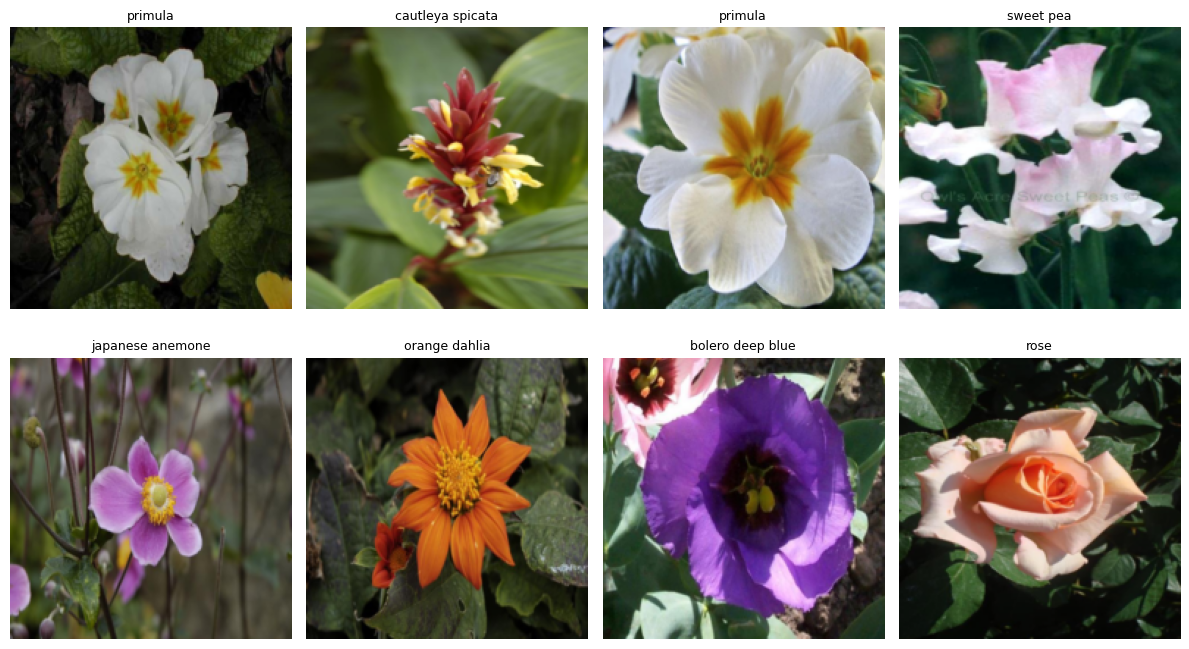

In [2]:
# Class names: TensorFlow Datasets oxford_flowers102_dataset_builder.py
class_names = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea",
    "english marigold", "tiger lily", "moon orchid", "bird of paradise", "monkshood",
    "globe thistle", "snapdragon", "colt's foot", "king protea", "spear thistle",
    "yellow iris", "globe-flower", "purple coneflower", "peruvian lily", "balloon flower",
    "giant white arum lily", "fire lily", "pincushion flower", "fritillary", "red ginger",
    "grape hyacinth", "corn poppy", "prince of wales feathers", "stemless gentian",
    "artichoke", "sweet william", "carnation", "garden phlox", "love in the mist",
    "mexican aster", "alpine sea holly", "ruby-lipped cattleya", "cape flower",
    "great masterwort", "siam tulip", "lenten rose", "barbeton daisy", "daffodil",
    "sword lily", "poinsettia", "bolero deep blue", "wallflower", "marigold", "buttercup",
    "oxeye daisy", "common dandelion", "petunia", "wild pansy", "primula", "sunflower",
    "pelargonium", "bishop of llandaff", "gaura", "geranium", "orange dahlia",
    "pink-yellow dahlia?", "cautleya spicata", "japanese anemone", "black-eyed susan",
    "silverbush", "californian poppy", "osteospermum", "spring crocus", "bearded iris",
    "windflower", "tree poppy", "gazania", "azalea", "water lily", "rose", "thorn apple",
    "morning glory", "passion flower", "lotus", "toad lily", "anthurium", "frangipani",
    "clematis", "hibiscus", "columbine", "desert-rose", "tree mallow", "magnolia",
    "cyclamen", "watercress", "canna lily", "hippeastrum", "bee balm", "ball moss",
    "foxglove", "bougainvillea", "camellia", "mallow", "mexican petunia", "bromelia",
    "blanket flower", "trumpet creeper", "blackberry lily"
]
assert len(class_names) == 102
print("Class | Name | Small | Full | Validation")
for label in range(102):
    small_count = int(np.sum(train_labels[small_indices] == label))
    full_count = int(np.sum(train_labels == label))
    assert small_count == 5 and full_count == 10
    print(label, class_names[label], small_count, full_count, 10)

sample_indices = np.random.RandomState(SEED).choice(len(train_eval_data), 8, replace=False)
plt.figure(figsize=(12, 7))
for i, index in enumerate(sample_indices):
    image, label = train_eval_data[int(index)]
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image * np.array(STD) + np.array(MEAN), 0, 1)
    plt.subplot(2, 4, i+1)
    plt.imshow(image)
    plt.title(textwrap.fill(class_names[label], 22), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()
plt.close()


In [3]:
METHODS = ["Scratch", "FeatureExtraction", "FineTuning"]

def count_parameters(model, only_trainable=False):
    return sum(p.numel() for p in model.parameters() if not only_trainable or p.requires_grad)

def make_model(method):
    if method == "Scratch":
        model = models.resnet18(weights=None)
    else:
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        for parameter in model.parameters():
            parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 102)
    return model.to(device)

def unfreeze_layer4(model):
    for parameter in model.layer4.parameters():
        parameter.requires_grad = True
    for parameter in model.fc.parameters():
        parameter.requires_grad = True

def freeze_bn_statistics(model):
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

def bn_statistics(model):
    values = {}
    for name, module in model.named_modules():
        if isinstance(module, nn.BatchNorm2d):
            values[name] = (module.running_mean.clone(), module.running_var.clone(),
                            module.num_batches_tracked.clone())
    return values

for method in METHODS:
    set_seed()
    model = make_model(method)
    model.eval()
    with torch.no_grad():
        output = model(torch.zeros(2, 3, 192, 192).to(device))
    assert list(output.shape) == [2, 102]
    print("\n", method, "Output:", list(output.shape), "Total parameters:", count_parameters(model),
          "FC parameters:", count_parameters(model.fc), "Initially trainable:", count_parameters(model, True))
    for group_name in ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]:
        group = getattr(model, group_name)
        print(group_name, "requires_grad:", sorted(set(p.requires_grad for p in group.parameters())))
    if method == "FineTuning":
        unfreeze_layer4(model)
        print("Trainable after unfreezing layer4:", count_parameters(model, True))
        for group_name in ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]:
            group = getattr(model, group_name)
            print(group_name, "requires_grad:", sorted(set(p.requires_grad for p in group.parameters())))
    del model



 Scratch Output: [2, 102] Total parameters: 11228838 FC parameters: 52326 Initially trainable: 11228838
conv1 requires_grad: [True]
bn1 requires_grad: [True]
layer1 requires_grad: [True]
layer2 requires_grad: [True]
layer3 requires_grad: [True]
layer4 requires_grad: [True]
fc requires_grad: [True]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]



 FeatureExtraction Output: [2, 102] Total parameters: 11228838 FC parameters: 52326 Initially trainable: 52326
conv1 requires_grad: [False]
bn1 requires_grad: [False]
layer1 requires_grad: [False]
layer2 requires_grad: [False]
layer3 requires_grad: [False]
layer4 requires_grad: [False]
fc requires_grad: [True]

 FineTuning Output: [2, 102] Total parameters: 11228838 FC parameters: 52326 Initially trainable: 52326
conv1 requires_grad: [False]
bn1 requires_grad: [False]
layer1 requires_grad: [False]
layer2 requires_grad: [False]
layer3 requires_grad: [False]
layer4 requires_grad: [False]
fc requires_grad: [True]
Trainable after unfreezing layer4: 8446054
conv1 requires_grad: [False]
bn1 requires_grad: [False]
layer1 requires_grad: [False]
layer2 requires_grad: [False]
layer3 requires_grad: [False]
layer4 requires_grad: [True]
fc requires_grad: [True]


In [4]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_labels, all_predictions = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            output = model(x)
            predictions = output.argmax(1)
            total_loss += criterion(output, y).item() * y.size(0)
            correct += (predictions == y).sum().item()
            total += y.size(0)
            all_labels.extend(y.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())
    return {"loss": total_loss / total, "accuracy": correct / total,
            "macro_f1": f1_score(all_labels, all_predictions, labels=list(range(102)),
                                  average="macro", zero_division=0),
            "labels": np.array(all_labels), "predictions": np.array(all_predictions)}

def train_experiment(size, method):
    set_seed()
    model = make_model(method)
    train_loader, train_eval_loader = make_loaders(size)
    if method == "Scratch":
        optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=WEIGHT_DECAY)
    else:
        optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001, weight_decay=WEIGHT_DECAY)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
    trainable_counts = []
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    initial_bn = bn_statistics(model) if method != "Scratch" else None
    synchronize()
    start = time.perf_counter()

    for epoch in range(EPOCHS):
        if method == "FineTuning" and epoch == 3:
            unfreeze_layer4(model)
            optimizer = torch.optim.Adam([
                {"params": model.layer4.parameters(), "lr": 0.00001},
                {"params": model.fc.parameters(), "lr": 0.0001}
            ], weight_decay=WEIGHT_DECAY)
            print(size, method, "unfroze layer4 + fc at epoch 4")

        trainable_counts.append(count_parameters(model, True))
        model.train()
        if method != "Scratch":
            freeze_bn_statistics(model)
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        train_metrics = evaluate(model, train_eval_loader)
        val_metrics = evaluate(model, val_loader)
        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_metrics["accuracy"])
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])
        if val_metrics["loss"] < best_loss:
            best_loss = val_metrics["loss"]
            best_epoch = epoch+1
            best_state = copy.deepcopy(model.state_dict())
        print(f"{size} {method} {epoch+1:02d}/{EPOCHS} | Train Loss {train_metrics['loss']:.4f} Acc {train_metrics['accuracy']:.4f} | Val Loss {val_metrics['loss']:.4f} Acc {val_metrics['accuracy']:.4f} Macro-F1 {val_metrics['macro_f1']:.4f}")

    synchronize()
    seconds = time.perf_counter() - start
    if method != "Scratch":
        final_bn = bn_statistics(model)
        for name in initial_bn:
            for before, after in zip(initial_bn[name], final_bn[name]):
                assert torch.equal(before, after), "BatchNorm statistics changed: " + name
        print(size, method, "BatchNorm running statistics stayed fixed.")

    model.load_state_dict(best_state)
    model.eval()
    max_acc = max(history["val_acc"])
    summary = {"size": size, "method": method, "training_images": len(data_indices[size]),
               "total_parameters": count_parameters(model),
               "phase1_trainable_parameters": trainable_counts[0],
               "final_phase_trainable_parameters": trainable_counts[-1],
               "maximum_trainable_parameters": max(trainable_counts),
               "trainable_at_selected_epoch": trainable_counts[best_epoch-1],
               "minimum_validation_loss": best_loss, "best_loss_epoch": best_epoch,
               "checkpoint_train_accuracy": history["train_acc"][best_epoch-1],
               "checkpoint_validation_accuracy": history["val_acc"][best_epoch-1],
               "checkpoint_validation_macro_f1": history["val_macro_f1"][best_epoch-1],
               "maximum_validation_accuracy": max_acc,
               "maximum_accuracy_epoch": history["val_acc"].index(max_acc)+1,
               "training_including_evaluation_seconds": seconds}
    print(summary)
    return {"model": model, "history": history, "summary": summary}


In [5]:
results = {}
for size in ["Small", "Full"]:
    for method in METHODS:
        results[size + "_" + method] = train_experiment(size, method)


Small Scratch 01/10 | Train Loss 4.0395 Acc 0.0745 | Val Loss 4.4263 Acc 0.0422 Macro-F1 0.0161
Small Scratch 02/10 | Train Loss 3.7610 Acc 0.1275 | Val Loss 4.5827 Acc 0.0775 Macro-F1 0.0341
Small Scratch 03/10 | Train Loss 2.8766 Acc 0.2353 | Val Loss 3.9215 Acc 0.1206 Macro-F1 0.0734
Small Scratch 04/10 | Train Loss 2.6426 Acc 0.2863 | Val Loss 3.6732 Acc 0.1539 Macro-F1 0.1058
Small Scratch 05/10 | Train Loss 3.4040 Acc 0.2373 | Val Loss 4.6517 Acc 0.1118 Macro-F1 0.0859
Small Scratch 06/10 | Train Loss 2.2143 Acc 0.3667 | Val Loss 3.6290 Acc 0.1657 Macro-F1 0.1252
Small Scratch 07/10 | Train Loss 2.4196 Acc 0.3549 | Val Loss 3.9025 Acc 0.1422 Macro-F1 0.1235
Small Scratch 08/10 | Train Loss 2.1430 Acc 0.3980 | Val Loss 3.9747 Acc 0.1676 Macro-F1 0.1398
Small Scratch 09/10 | Train Loss 1.8095 Acc 0.5000 | Val Loss 3.7110 Acc 0.1755 Macro-F1 0.1556
Small Scratch 10/10 | Train Loss 1.4430 Acc 0.5980 | Val Loss 3.5318 Acc 0.2127 Macro-F1 0.1730
{'size': 'Small', 'method': 'Scratch', '

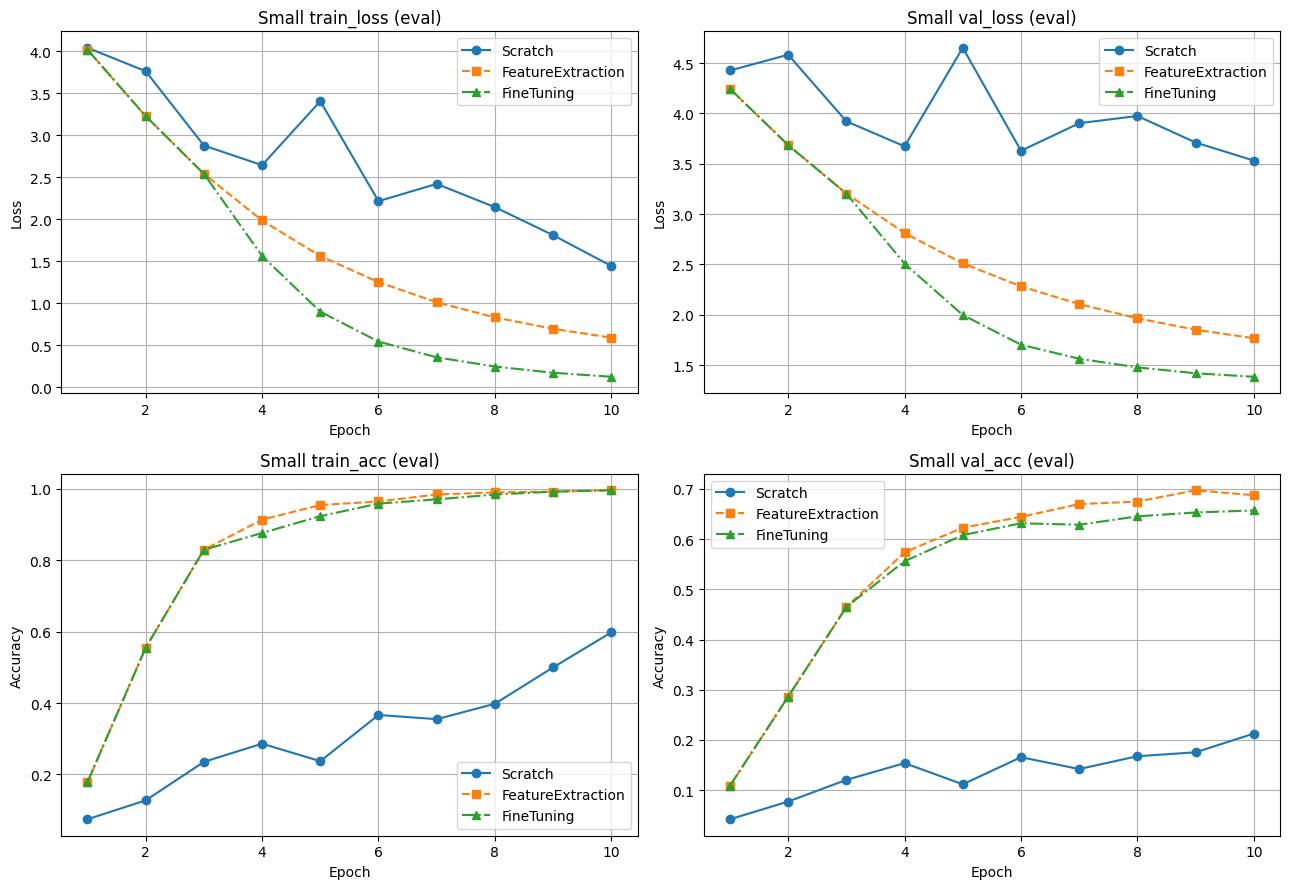

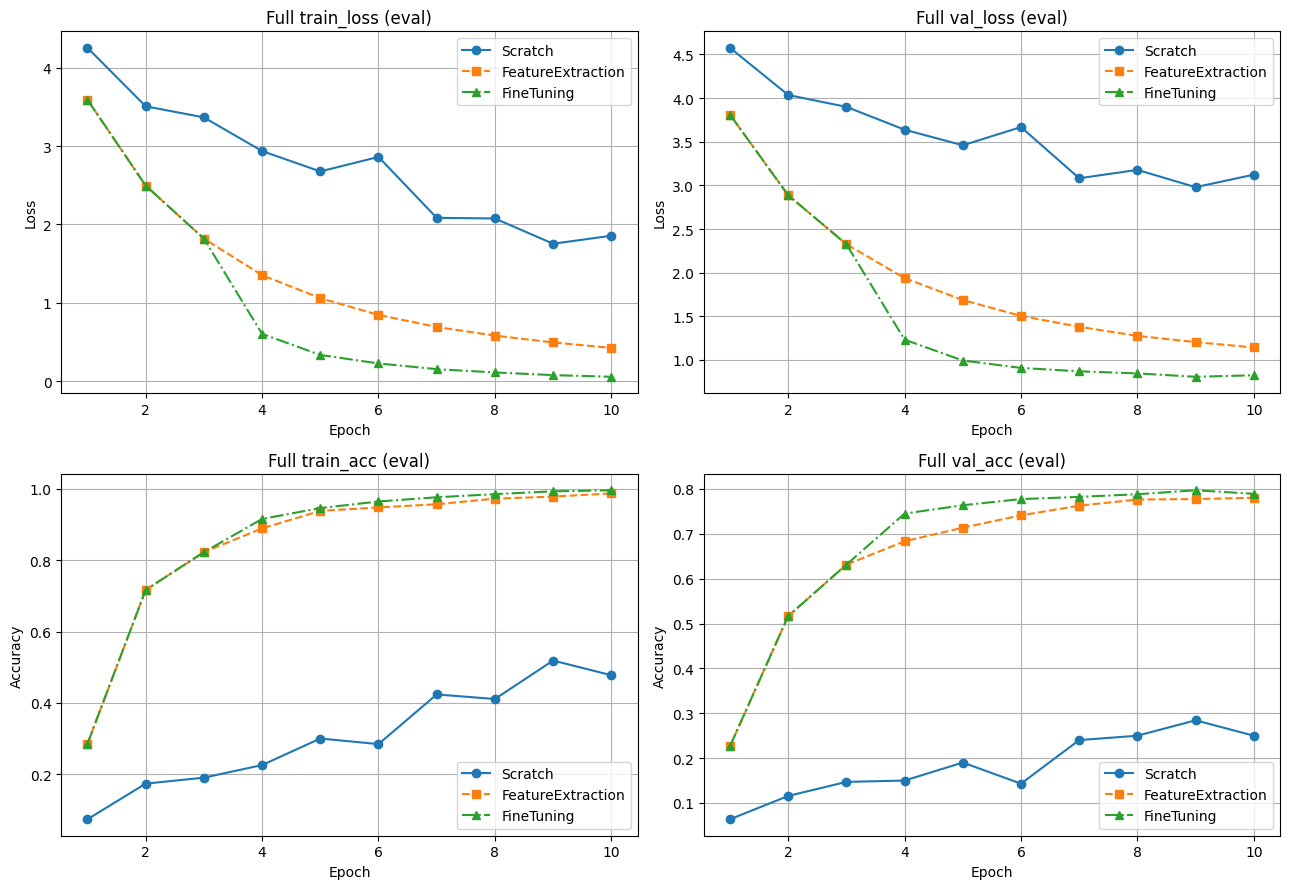

Small Scratch            | Params 11228838 | Trainable phases 11228838 / 11228838 | Val Loss 3.5318 at epoch 10 | Checkpoint Acc 21.27% Macro-F1 0.1730 | Max Acc 21.27% at epoch 10 | Time 125.02s
Small FeatureExtraction  | Params 11228838 | Trainable phases 52326 / 52326 | Val Loss 1.7680 at epoch 10 | Checkpoint Acc 68.73% Macro-F1 0.6770 | Max Acc 69.71% at epoch 9 | Time 122.85s
Small FineTuning         | Params 11228838 | Trainable phases 52326 / 8446054 | Val Loss 1.3851 at epoch 10 | Checkpoint Acc 65.69% Macro-F1 0.6446 | Max Acc 65.69% at epoch 10 | Time 123.87s
Full  Scratch            | Params 11228838 | Trainable phases 11228838 / 11228838 | Val Loss 2.9794 at epoch 9 | Checkpoint Acc 28.43% Macro-F1 0.2549 | Max Acc 28.43% at epoch 9 | Time 180.00s
Full  FeatureExtraction  | Params 11228838 | Trainable phases 52326 / 52326 | Val Loss 1.1425 at epoch 10 | Checkpoint Acc 78.04% Macro-F1 0.7767 | Max Acc 78.04% at epoch 10 | Time 180.77s
Full  FineTuning         | Params 11228

In [6]:
for size in ["Small", "Full"]:
    plt.figure(figsize=(13, 9))
    for panel, metric in enumerate(["train_loss", "val_loss", "train_acc", "val_acc"]):
        plt.subplot(2, 2, panel+1)
        for method, style, marker in zip(METHODS, ["-", "--", "-."], ["o", "s", "^"]):
            history = results[size + "_" + method]["history"]
            plt.plot(range(1, EPOCHS+1), history[metric], linestyle=style, marker=marker, label=method)
        plt.title(size + " " + metric + " (eval)")
        plt.xlabel("Epoch")
        plt.ylabel("Loss" if "loss" in metric else "Accuracy")
        plt.legend()
        plt.grid(True)
    plt.tight_layout()
    plt.show()
    plt.close()

summary_rows = [result["summary"] for result in results.values()]
for row in summary_rows:
    print(f"{row['size']:5} {row['method']:18} | Params {row['total_parameters']} | Trainable phases {row['phase1_trainable_parameters']} / {row['final_phase_trainable_parameters']} | Val Loss {row['minimum_validation_loss']:.4f} at epoch {row['best_loss_epoch']} | Checkpoint Acc {100*row['checkpoint_validation_accuracy']:.2f}% Macro-F1 {row['checkpoint_validation_macro_f1']:.4f} | Max Acc {100*row['maximum_validation_accuracy']:.2f}% at epoch {row['maximum_accuracy_epoch']} | Time {row['training_including_evaluation_seconds']:.2f}s")

for method in METHODS:
    small = results["Small_" + method]["summary"]
    full = results["Full_" + method]["summary"]
    print(method, "Full minus Small Accuracy (percentage points):",
          100*(full["checkpoint_validation_accuracy"] - small["checkpoint_validation_accuracy"]),
          "Macro-F1 difference:", full["checkpoint_validation_macro_f1"] - small["checkpoint_validation_macro_f1"])


In [7]:
fixed_batch = torch.zeros(BATCH_SIZE, 3, 192, 192).to(device)

def forward_time(model):
    model.eval()
    measurements = []
    with torch.inference_mode():
        for _ in range(10):
            model(fixed_batch)
        synchronize()
        for _ in range(30):
            synchronize()
            start = time.perf_counter()
            model(fixed_batch)
            synchronize()
            measurements.append((time.perf_counter() - start)*1000)
    return float(np.median(measurements))

full_cost_rows = []
for method in METHODS:
    result = results["Full_" + method]
    row = dict(result["summary"])
    row["median_forward_ms"] = forward_time(result["model"])
    full_cost_rows.append(row)
    print(row)


{'size': 'Full', 'method': 'Scratch', 'training_images': 1020, 'total_parameters': 11228838, 'phase1_trainable_parameters': 11228838, 'final_phase_trainable_parameters': 11228838, 'maximum_trainable_parameters': 11228838, 'trainable_at_selected_epoch': 11228838, 'minimum_validation_loss': 2.979409922805487, 'best_loss_epoch': 9, 'checkpoint_train_accuracy': 0.5186274509803922, 'checkpoint_validation_accuracy': 0.28431372549019607, 'checkpoint_validation_macro_f1': 0.2548767912986857, 'maximum_validation_accuracy': 0.28431372549019607, 'maximum_accuracy_epoch': 9, 'training_including_evaluation_seconds': 180.00078240999994, 'median_forward_ms': 20.476540000004206}
{'size': 'Full', 'method': 'FeatureExtraction', 'training_images': 1020, 'total_parameters': 11228838, 'phase1_trainable_parameters': 52326, 'final_phase_trainable_parameters': 52326, 'maximum_trainable_parameters': 52326, 'trainable_at_selected_epoch': 52326, 'minimum_validation_loss': 1.1425415193333346, 'best_loss_epoch': 1

{'model': 'Full_FeatureExtraction', 'class_id': 0, 'class_name': 'pink primrose', 'accuracy': 0.7, 'f1': 0.7777777777777778, 'errors': 3}
{'model': 'Full_FeatureExtraction', 'class_id': 1, 'class_name': 'hard-leaved pocket orchid', 'accuracy': 0.8, 'f1': 0.8888888888888888, 'errors': 2}
{'model': 'Full_FeatureExtraction', 'class_id': 2, 'class_name': 'canterbury bells', 'accuracy': 0.5, 'f1': 0.47619047619047616, 'errors': 5}
{'model': 'Full_FeatureExtraction', 'class_id': 3, 'class_name': 'sweet pea', 'accuracy': 0.2, 'f1': 0.3076923076923077, 'errors': 8}
{'model': 'Full_FeatureExtraction', 'class_id': 4, 'class_name': 'english marigold', 'accuracy': 0.8, 'f1': 0.8, 'errors': 2}
{'model': 'Full_FeatureExtraction', 'class_id': 5, 'class_name': 'tiger lily', 'accuracy': 1.0, 'f1': 0.9523809523809523, 'errors': 0}
{'model': 'Full_FeatureExtraction', 'class_id': 6, 'class_name': 'moon orchid', 'accuracy': 0.8, 'f1': 0.8421052631578947, 'errors': 2}
{'model': 'Full_FeatureExtraction', 'cl

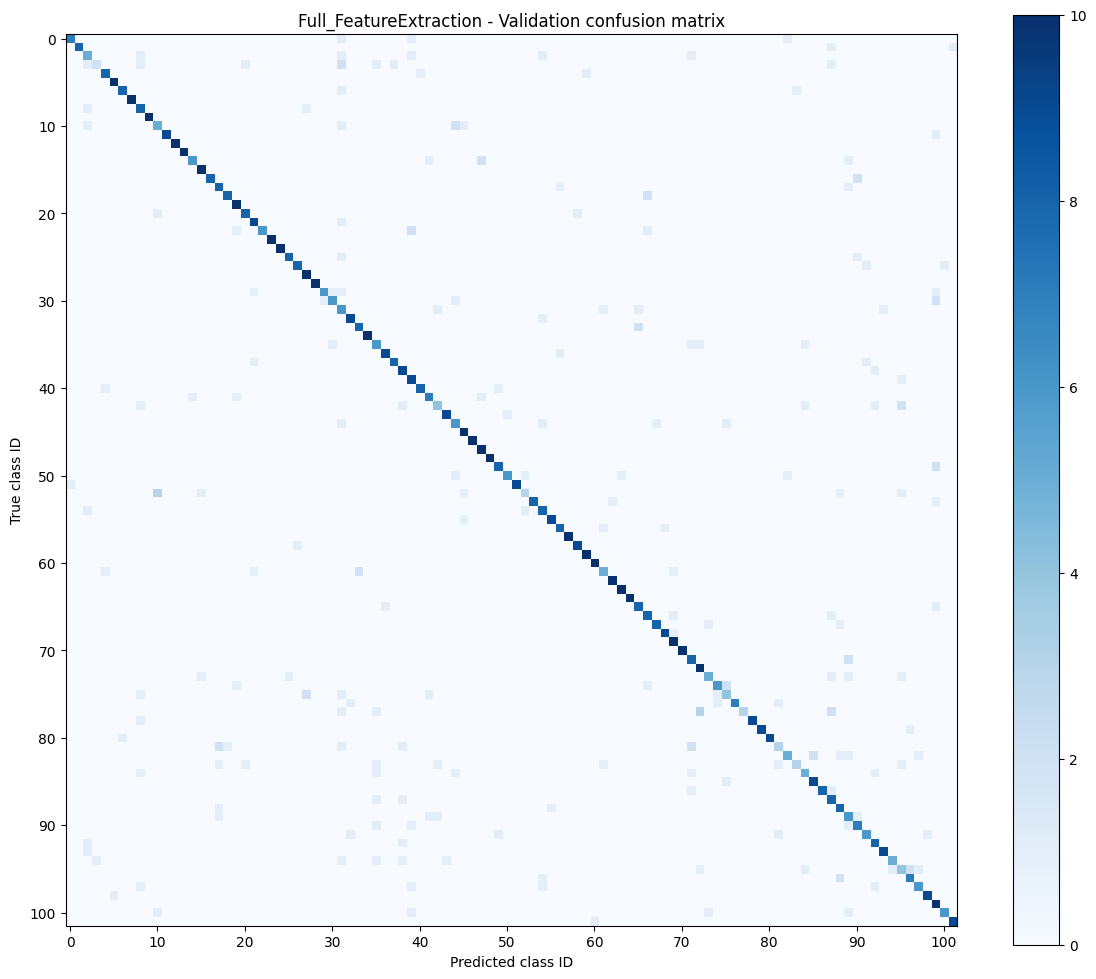

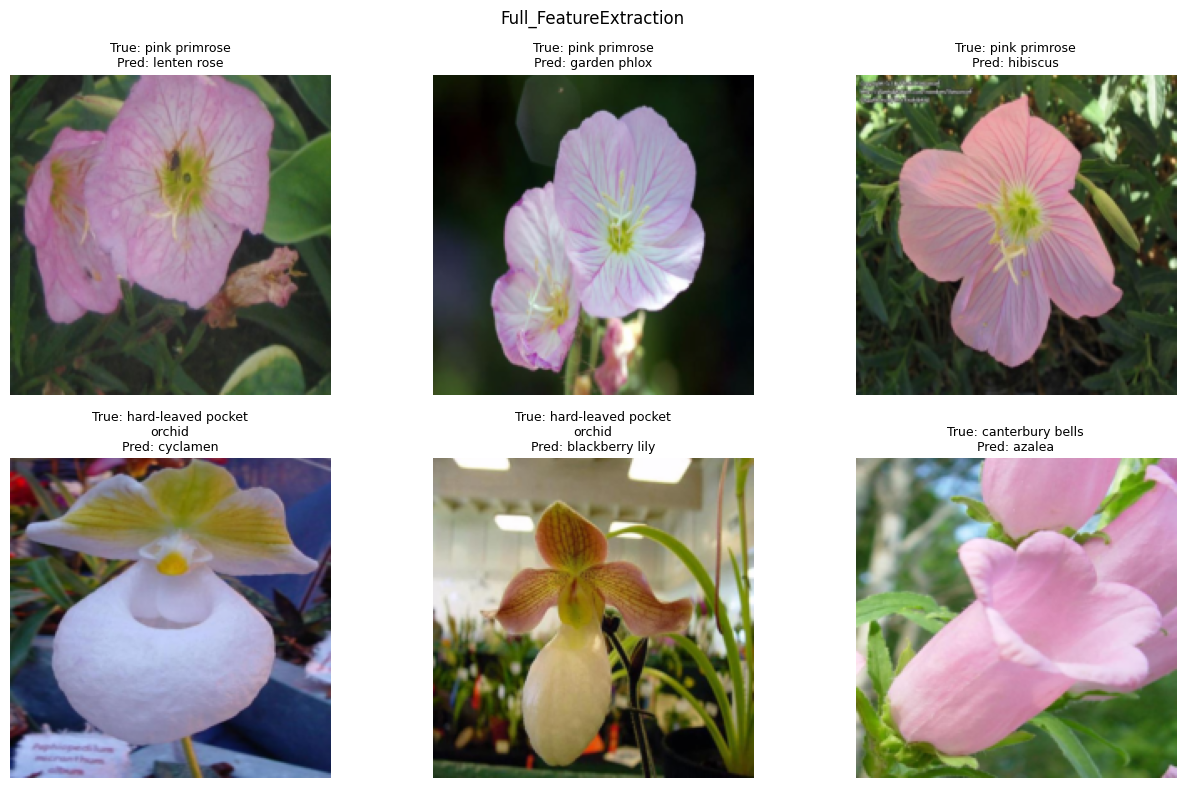

{'model': 'Full_FineTuning', 'class_id': 0, 'class_name': 'pink primrose', 'accuracy': 0.8, 'f1': 0.8888888888888888, 'errors': 2}
{'model': 'Full_FineTuning', 'class_id': 1, 'class_name': 'hard-leaved pocket orchid', 'accuracy': 0.7, 'f1': 0.8235294117647058, 'errors': 3}
{'model': 'Full_FineTuning', 'class_id': 2, 'class_name': 'canterbury bells', 'accuracy': 0.7, 'f1': 0.5185185185185185, 'errors': 3}
{'model': 'Full_FineTuning', 'class_id': 3, 'class_name': 'sweet pea', 'accuracy': 0.1, 'f1': 0.15384615384615385, 'errors': 9}
{'model': 'Full_FineTuning', 'class_id': 4, 'class_name': 'english marigold', 'accuracy': 0.8, 'f1': 0.7619047619047619, 'errors': 2}
{'model': 'Full_FineTuning', 'class_id': 5, 'class_name': 'tiger lily', 'accuracy': 1.0, 'f1': 0.9523809523809523, 'errors': 0}
{'model': 'Full_FineTuning', 'class_id': 6, 'class_name': 'moon orchid', 'accuracy': 0.8, 'f1': 0.8421052631578947, 'errors': 2}
{'model': 'Full_FineTuning', 'class_id': 7, 'class_name': 'bird of paradi

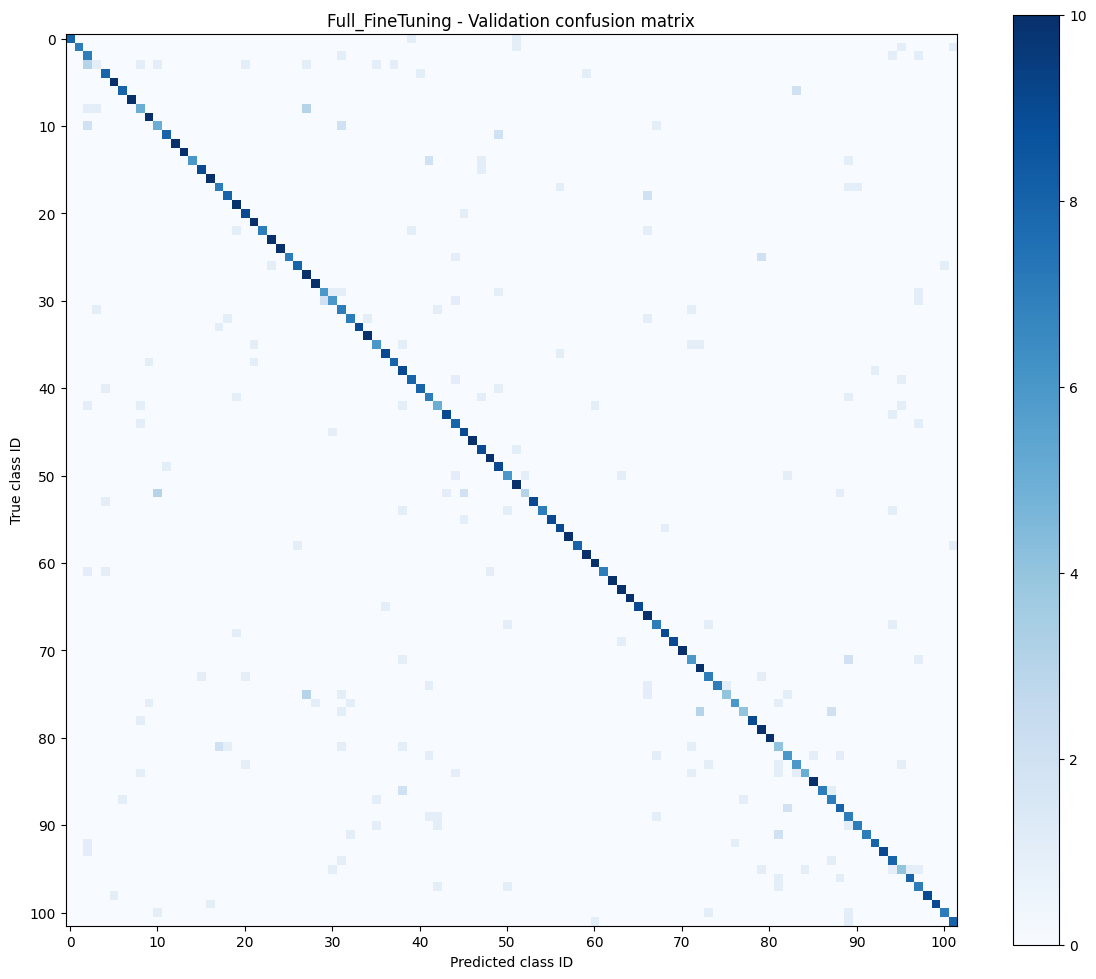

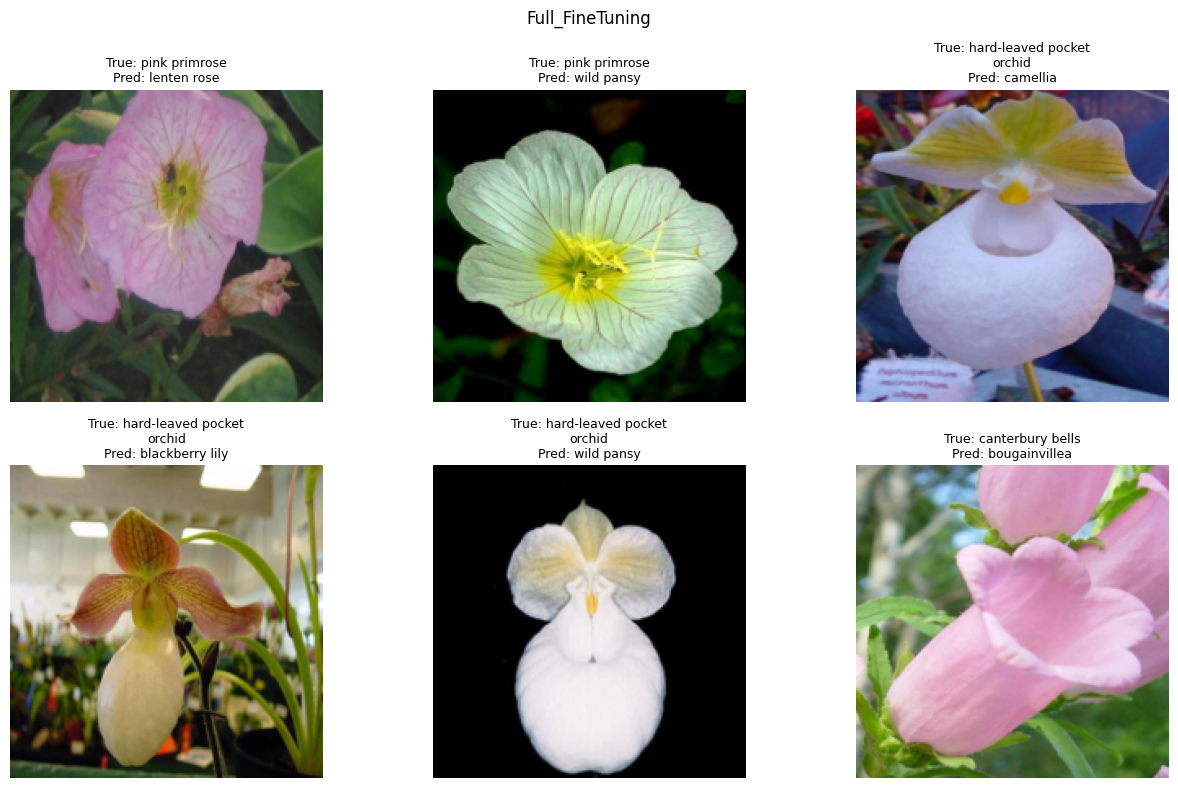

In [8]:
error_summaries = {}
class_rows = []
for method in ["FeatureExtraction", "FineTuning"]:
    name = "Full_" + method
    model = results[name]["model"]
    metrics = evaluate(model, val_loader)
    labels, predictions = metrics["labels"], metrics["predictions"]
    cm = confusion_matrix(labels, predictions, labels=list(range(102)))
    counts = cm.sum(axis=1)
    correct = cm.diagonal()
    errors = counts - correct
    class_f1 = f1_score(labels, predictions, labels=list(range(102)), average=None, zero_division=0)
    assert np.all(counts == 10)
    for label in range(102):
        row = {"model": name, "class_id": label, "class_name": class_names[label],
               "accuracy": float(correct[label]/counts[label]), "f1": float(class_f1[label]),
               "errors": int(errors[label])}
        class_rows.append(row)
        print(row)

    top_classes = [i for i in np.argsort(-errors) if errors[i] > 0][:5]
    pairs = []
    for i in range(102):
        for j in range(i+1, 102):
            count = int(cm[i,j] + cm[j,i])
            if count > 0:
                pairs.append({"class1": class_names[i], "class2": class_names[j],
                              "total_confusions": count, "class1_to_class2": int(cm[i,j]),
                              "class2_to_class1": int(cm[j,i])})
    pairs.sort(key=lambda row: row["total_confusions"], reverse=True)

    examples = []
    for index in np.where(labels != predictions)[0][:6]:
        image, label = val_data[int(index)]
        examples.append((image, label, int(predictions[index])))
    error_summaries[name] = {
        "five_classes_with_most_errors": [{"class": class_names[i], "errors": int(errors[i])} for i in top_classes],
        "five_most_confused_pairs": pairs[:5],
        "shown_examples": [{"true": class_names[y], "predicted": class_names[p]} for image, y, p in examples]
    }
    print(name, error_summaries[name])

    plt.figure(figsize=(12, 10))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(0, 102, 10))
    plt.yticks(range(0, 102, 10))
    plt.xlabel("Predicted class ID")
    plt.ylabel("True class ID")
    plt.title(name + " - Validation confusion matrix")
    plt.tight_layout()
    plt.show()
    plt.close()

    if examples:
        plt.figure(figsize=(13, 8))
        for i, (image, label, prediction) in enumerate(examples):
            image = image.permute(1, 2, 0).numpy()
            image = np.clip(image * np.array(STD) + np.array(MEAN), 0, 1)
            plt.subplot(2, 3, i+1)
            plt.imshow(image)
            title = "True: " + class_names[label] + "\nPred: " + class_names[prediction]
            plt.title(textwrap.fill(title.split("\n")[0], 28) + "\n" + textwrap.fill(title.split("\n")[1], 28), fontsize=9)
            plt.axis("off")
        plt.suptitle(name)
        plt.tight_layout()
        plt.show()
        plt.close()


In [9]:
best_f1 = max(row["checkpoint_validation_macro_f1"] for row in summary_rows)
close_models = [row for row in summary_rows
                if best_f1 - row["checkpoint_validation_macro_f1"] <= 0.01 + 1e-12]
chosen = min(close_models, key=lambda row: (row["training_including_evaluation_seconds"],
                                           row["maximum_trainable_parameters"]))
selected_name = chosen["size"] + "_" + chosen["method"]
selected_model = results[selected_name]["model"]
print("Best checkpoint Validation Macro-F1:", best_f1)
print("Within 0.01:", [row["size"] + "_" + row["method"] for row in close_models])
print("Selected model:", selected_name)
print(chosen)


Best checkpoint Validation Macro-F1: 0.7945264198690027
Within 0.01: ['Full_FineTuning']
Selected model: Full_FineTuning
{'size': 'Full', 'method': 'FineTuning', 'training_images': 1020, 'total_parameters': 11228838, 'phase1_trainable_parameters': 52326, 'final_phase_trainable_parameters': 8446054, 'maximum_trainable_parameters': 8446054, 'trainable_at_selected_epoch': 8446054, 'minimum_validation_loss': 0.8070974148955999, 'best_loss_epoch': 9, 'checkpoint_train_accuracy': 0.9931372549019608, 'checkpoint_validation_accuracy': 0.7970588235294118, 'checkpoint_validation_macro_f1': 0.7945264198690027, 'maximum_validation_accuracy': 0.7970588235294118, 'maximum_accuracy_epoch': 9, 'training_including_evaluation_seconds': 180.67613656799995}


In [10]:
if "final_test_result_ex4" not in globals():
    test_data = datasets.Flowers102("data", split="test", download=False, transform=eval_transform)
    assert len(test_data) == 6149
    test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
    metrics = evaluate(selected_model, test_loader)
    final_test_result_ex4 = {
        "model": selected_name, "seed": SEED, "checkpoint_epoch": chosen["best_loss_epoch"],
        "test_accuracy": metrics["accuracy"], "test_macro_f1": metrics["macro_f1"],
        "test_loss": metrics["loss"]
    }
print(final_test_result_ex4)


{'model': 'Full_FineTuning', 'seed': 42, 'checkpoint_epoch': 9, 'test_accuracy': 0.7715075622052366, 'test_macro_f1': 0.773939080630345, 'test_loss': 0.8508834752971272}
